# House Price Regression with Ridge and KNN

This tutorial supplements `regression_tutorial.ipynb` by comparing two regression methods:

- **Ridge Regression** as a regularized linear model
- **K-Nearest Neighbors Regression (KNN)**

We use scikit-learn's **California Housing** dataset, select model settings with a validation set, and report final performance on a held-out test set.

## Dataset size

California Housing contains **20,640 samples** and **8 numeric input features**. The target is the median house value for a California census block, expressed in units of **$100,000**. Including the target, the modeling table has 9 columns.

This is a **small-to-medium tabular dataset**, not a large dataset by modern machine-learning standards. It is easy to hold in memory on a normal laptop. KNN stores the training samples and can become slower at prediction as the dataset grows.

Each row represents a **census block group**, not one individual house. The columns are:

| Column | Role | Meaning |
|---|---|---|
| `MedInc` | Input | Median household income in the block group, in units of approximately $10,000; for example, 8.3 represents about $83,000. |
| `HouseAge` | Input | Median age of the houses in the block group, in years. |
| `AveRooms` | Input | Average rooms per household: total rooms divided by the number of households. |
| `AveBedrms` | Input | Average bedrooms per household: total bedrooms divided by the number of households. |
| `Population` | Input | Total population of the block group. |
| `AveOccup` | Input | Average occupants per household: population divided by the number of households. |
| `Latitude` | Input | Geographic latitude; larger values are farther north. |
| `Longitude` | Input | Geographic longitude; in California, more negative values are generally farther west. |
| `MedHouseVal` | Target | Median house value in units of $100,000; for example, 2.5 represents about $250,000. |

> `MedHouseVa` in a narrow table display is a truncated rendering of `MedHouseVal`. The target is capped at about $500,000, so predictions near the upper boundary should be interpreted carefully.

Dataset documentation: https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset

## 1. Imports

The dataset is downloaded automatically by scikit-learn the first time this notebook is run. Later runs use the local scikit-learn cache.

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load and inspect the data

In [2]:
housing = fetch_california_housing(as_frame=True)
X = housing.data.copy()
y = housing.target.copy()

memory_mb = housing.frame.memory_usage(deep=True).sum() / 1024**2
summary = pd.Series({
    "Samples": X.shape[0],
    "Input features": X.shape[1],
    "Missing values": int(X.isna().sum().sum() + y.isna().sum()),
    "In-memory table size (MiB)": round(memory_mb, 2),
}, name="California Housing")
summary.to_frame()

,California Housing
Samples,20640.00
Input features,8.00
Missing values,0.00
In-memory table size (MiB),1.42


In [3]:
display(housing.frame.head())
display(housing.frame.describe().T.round(3))

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.0,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
MedHouseVal,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000


## 3. Create training, validation, and test sets

We use a **70% / 15% / 15%** split:

- **Training set:** fit model parameters.
- **Validation set:** compare models and choose hyperparameters.
- **Test set:** report final performance only after all choices are fixed.

Keeping the test set separate prevents its information from influencing model selection.

In [4]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

print(f"Training samples: {len(X_train):,}")
print(f"Validation samples: {len(X_val):,}")
print(f"Test samples:     {len(X_test):,}")

Training samples: 14,448
Validation samples: 3,096
Test samples:     3,096


## 4. Scale the features as a separate step

KNN uses feature distances, so features with large numeric ranges can dominate the result. Ridge is also scale-sensitive because its penalty acts on coefficient sizes. `StandardScaler` centers each feature around zero and scales it to unit variance.

The important leakage rule is:

1. Call `fit_transform` on the **training set only**.
2. Call `transform` on validation and test sets using the same fitted scaler.

Never fit the scaler on validation/test data.

In [5]:
scaler = StandardScaler()

# Learn the mean and standard deviation from the training set only.
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X.columns, index=X_train.index
)

# Reuse those training-set statistics; do not fit again.
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val), columns=X.columns, index=X_val.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X.columns, index=X_test.index
)

scaling_check = pd.DataFrame({
    "Mean before scaling": X_train.mean(),
    "Mean after scaling": X_train_scaled.mean(),
    "Std after scaling": X_train_scaled.std(ddof=0),
})
scaling_check.round(3)

,Mean before scaling,Mean after scaling,Std after scaling
MedInc,3.877,-0.0,1.0
HouseAge,28.575,-0.0,1.0
AveRooms,5.438,0.0,1.0
AveBedrms,1.098,0.0,1.0
Population,1427.927,0.0,1.0
AveOccup,3.119,0.0,1.0
Latitude,35.651,-0.0,1.0
Longitude,-119.584,0.0,1.0


## 5. Train and validate each regressor separately

Each regressor has its own code cell. Ridge is fitted once, while the KNN cell compares several `n_neighbors` values. All choices use validation RMSE, while the test set remains untouched until the final summary.

The per-model tables report MAE, RMSE, R², fitting time, and validation prediction time. These are reasonable teaching defaults, not universally optimal hyperparameters.

In [6]:
# Ridge Regression: squared L2 prediction loss plus an L2 coefficient penalty.
# alpha controls the regularization strength; larger alpha means more shrinkage.
ridge_model = Ridge(alpha=1.0)

fit_start = perf_counter()
ridge_model.fit(X_train_scaled, y_train)
ridge_fit_seconds = perf_counter() - fit_start

predict_start = perf_counter()
ridge_val_prediction = ridge_model.predict(X_val_scaled)
ridge_predict_seconds = perf_counter() - predict_start

ridge_validation_result = {
    "Model": "Ridge Regression",
    "MAE ($)": mean_absolute_error(y_val, ridge_val_prediction) * 100_000,
    "RMSE ($)": np.sqrt(mean_squared_error(y_val, ridge_val_prediction)) * 100_000,
    "R²": r2_score(y_val, ridge_val_prediction),
    "Fit time (s)": ridge_fit_seconds,
    "Prediction time (s)": ridge_predict_seconds,
}
pd.DataFrame([ridge_validation_result]).set_index("Model").style.format({
    "MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}", "R²": "{:.3f}",
    "Fit time (s)": "{:.3f}", "Prediction time (s)": "{:.3f}",
})

,MAE ($),RMSE ($),R²,Fit time (s),Prediction time (s)
Model,,,,,
Ridge Regression,"$53,345","$73,544",0.585,0.007,0.001


In [7]:
# KNN Regression: average the targets of nearby training samples.
# Small k is flexible; large k is smoother. Distance weights favor closer neighbors.
k_values = [3, 5, 7, 10, 15, 20, 30, 50]
knn_candidates = {}
knn_validation_predictions = {}
knn_tuning_results = []

for k in k_values:
    candidate = KNeighborsRegressor(
        n_neighbors=k,       # Number of nearby training samples used for prediction.
        weights="distance", # Closer neighbors receive more influence than distant ones.
        p=2,                 # Use Euclidean distance (p=1 would use Manhattan distance).
    )
    fit_start = perf_counter()
    candidate.fit(X_train_scaled, y_train)
    fit_seconds = perf_counter() - fit_start

    predict_start = perf_counter()
    y_val_pred = candidate.predict(X_val_scaled)
    predict_seconds = perf_counter() - predict_start

    knn_candidates[k] = candidate
    knn_validation_predictions[k] = y_val_pred
    knn_tuning_results.append({
        "n_neighbors": k,
        "MAE ($)": mean_absolute_error(y_val, y_val_pred) * 100_000,
        "RMSE ($)": np.sqrt(mean_squared_error(y_val, y_val_pred)) * 100_000,
        "R²": r2_score(y_val, y_val_pred),
        "Fit time (s)": fit_seconds,
        "Prediction time (s)": predict_seconds,
    })

knn_tuning_df = pd.DataFrame(knn_tuning_results).set_index("n_neighbors")
best_k = int(knn_tuning_df["RMSE ($)"].idxmin())
knn_model = knn_candidates[best_k]
knn_val_prediction = knn_validation_predictions[best_k]
best_knn_row = knn_tuning_df.loc[best_k]
knn_validation_result = {
    "Model": f"KNN (k={best_k})",
    **best_knn_row.to_dict(),
}

print(f"Best KNN n_neighbors by validation RMSE: {best_k}")
knn_tuning_df.style.format({
    "MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}", "R²": "{:.3f}",
    "Fit time (s)": "{:.3f}", "Prediction time (s)": "{:.3f}",
}).highlight_min(subset=["RMSE ($)"], color="#c6efce")

Best KNN n_neighbors by validation RMSE: 10


,MAE ($),RMSE ($),R²,Fit time (s),Prediction time (s)
n_neighbors,,,,,
3,"$45,994","$69,063",0.634,0.007,0.067
5,"$44,652","$66,768",0.658,0.005,0.073
7,"$44,301","$66,168",0.664,0.003,0.064
10,"$44,071","$65,676",0.669,0.003,0.057
15,"$44,474","$65,768",0.668,0.003,0.064
20,"$45,080","$66,177",0.664,0.003,0.070
30,"$45,697","$66,549",0.660,0.003,0.083
50,"$46,869","$67,557",0.650,0.003,0.101


## 6. Final summary

The last cell combines the individual validation results, identifies the overall best model by validation RMSE, evaluates the two fitted models on the test set exactly once, and plots actual versus predicted test values. Do not use test results to continue tuning.

Metrics: MAE and RMSE are better when lower; R² is better when higher. Points near the dashed diagonal in the plots are more accurate.

Best KNN n_neighbors: 10
Overall best model by validation RMSE: KNN (k=10)

Validation results


,MAE ($),RMSE ($),R²,Fit time (s),Prediction time (s)
Model,,,,,
Ridge Regression,"$53,345","$73,544",0.585,0.007,0.001
KNN (k=10),"$44,071","$65,676",0.669,0.003,0.057


Test results


,MAE ($),RMSE ($),R²,Prediction time (s)
Model,,,,
Ridge Regression,"$52,104","$72,126",0.607,0.001
KNN (k=10),"$42,909","$61,894",0.710,0.111


Selected model test RMSE: $61,894; test R²: 0.710


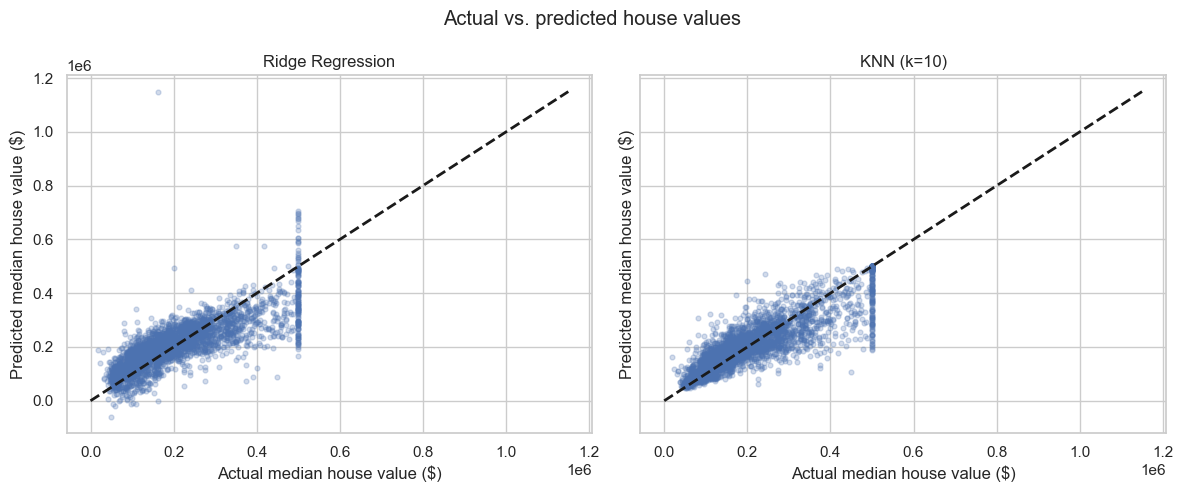

In [8]:
# Validation summary collected from the two separate regressor cells.
validation_results_df = pd.DataFrame([
    ridge_validation_result, knn_validation_result
]).set_index("Model")
best_validation_model = validation_results_df["RMSE ($)"].idxmin()
print(f"Best KNN n_neighbors: {best_k}")
print(f"Overall best model by validation RMSE: {best_validation_model}\n")
print("Validation results")
display(validation_results_df.style.format({
    "MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}", "R²": "{:.3f}",
    "Fit time (s)": "{:.3f}", "Prediction time (s)": "{:.3f}",
}).highlight_min(subset=["RMSE ($)"], color="#c6efce"))

# Final test evaluation. The test set is first used here.
fitted_models = {
    "Ridge Regression": ridge_model,
    f"KNN (k={best_k})": knn_model,
}
test_results = []
predictions = {}

for name, model in fitted_models.items():
    predict_start = perf_counter()
    y_pred = model.predict(X_test_scaled)
    predict_seconds = perf_counter() - predict_start
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    test_results.append({
        "Model": name,
        "MAE ($)": mae * 100_000,
        "RMSE ($)": rmse * 100_000,
        "R²": r2_score(y_test, y_pred),
        "Prediction time (s)": predict_seconds,
    })

test_results_df = pd.DataFrame(test_results).set_index("Model")

print("Test results")
display(test_results_df.style.format({
    "MAE ($)": "${:,.0f}", "RMSE ($)": "${:,.0f}", "R²": "{:.3f}",
    "Prediction time (s)": "{:.3f}",
}).apply(
    lambda row: ["background-color: #c6efce"] * len(row)
    if row.name == best_validation_model else [""] * len(row), axis=1
))
best_test_row = test_results_df.loc[best_validation_model]
print(
    f"Selected model test RMSE: ${best_test_row['RMSE ($)']:,.0f}; "
    f"test R²: {best_test_row['R²']:.3f}"
)

# Visual test-set summary.
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
axes = axes.ravel()
limits = [0, max(float(y_test.max()), max(float(p.max()) for p in predictions.values()))]

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test * 100_000, y_pred * 100_000, alpha=0.25, s=12)
    ax.plot(np.array(limits) * 100_000, np.array(limits) * 100_000, "k--", lw=2)
    ax.set_title(name)
    ax.set_xlabel("Actual median house value ($)")
    ax.set_ylabel("Predicted median house value ($)")

fig.suptitle("Actual vs. predicted house values")
plt.tight_layout()
plt.show()